# Studi Komparatif Model Generatif (Fashion-MNIST)

## 1. Setup

In [2]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy import linalg
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from torchvision.models import Inception_V3_Weights, inception_v3

In [3]:
SEED = 42
BATCH_SIZE = 128
RESULTS_DIR = "results"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASSES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

os.makedirs(RESULTS_DIR, exist_ok=True)
print("Device:", DEVICE)

Device: cuda


In [4]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

In [5]:
raw_train = datasets.FashionMNIST("data", train=True, download=True)
raw_test  = datasets.FashionMNIST("data", train=False, download=True)

all_imgs = torch.cat([raw_train.data, raw_test.data], dim=0).unsqueeze(1).float() / 255.0
all_lbls = torch.cat([raw_train.targets, raw_test.targets], dim=0)
full_ds = TensorDataset(all_imgs, all_lbls)

train_ds, val_ds, test_ds = random_split(
    full_ds, [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Split -> Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")

Split -> Train: 56000, Val: 7000, Test: 7000


## 2. Batasan MLP Classifier

In [6]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def extract_latent(self, x):
        h1 = F.relu(self.fc1(x.view(x.size(0), -1)))
        return F.relu(self.fc2(h1))

    def forward(self, x):
        return self.fc3(self.extract_latent(x))

    @torch.no_grad()
    def top_down_from_class(self, y_onehot):
        z_hat = F.relu(y_onehot @ self.fc3.weight)
        h_hat = F.relu(z_hat @ self.fc2.weight)
        return torch.sigmoid(h_hat @ self.fc1.weight).view(-1, 1, 28, 28)

    @torch.no_grad()
    def transpose_from_latent(self, z):
        h_hat = F.relu(z @ self.fc2.weight)
        return torch.sigmoid(h_hat @ self.fc1.weight).view(-1, 1, 28, 28)


class FrozenDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

In [7]:
set_seed()
mlp = MLPClassifier().to(DEVICE)
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)
t0 = time.perf_counter()

for epoch in range(25):
    mlp.train()
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad()
        F.cross_entropy(mlp(x), y).backward()
        opt.step()

mlp.eval()
correct = sum((mlp(x.to(DEVICE)).argmax(1) == y.to(DEVICE)).sum().item() for x, y in test_loader)
mlp_acc = correct / len(test_ds) * 100
print(f"[MLP Classifier] Akurasi Test Set: {mlp_acc:.2f}% ({time.perf_counter() - t0:.1f}s)")

ortho_errors = {}
for name, layer in [("W1", mlp.fc1), ("W2", mlp.fc2), ("W3", mlp.fc3)]:
    w = layer.weight.detach()
    err_col = torch.norm(w.T @ w - torch.eye(w.shape[1], device=DEVICE), p="fro").item()
    err_row = torch.norm(w @ w.T - torch.eye(w.shape[0], device=DEVICE), p="fro").item()
    ortho_errors[name] = {"shape": list(w.shape), "WTW_minus_I_fro": round(err_col, 4), "WWT_minus_I_fro": round(err_row, 4)}
    print(f"  {name} {tuple(w.shape)} -> ||W^T W - I||_F = {err_col:.2f}")

[MLP Classifier] Akurasi Test Set: 89.57% (42.4s)
  W1 (256, 784) -> ||W^T W - I||_F = 553.95
  W2 (64, 256) -> ||W^T W - I||_F = 72.13
  W3 (10, 64) -> ||W^T W - I||_F = 13.92


In [8]:
for p in mlp.parameters():
    p.requires_grad = False

set_seed()
frozen_dec = FrozenDecoder().to(DEVICE)
opt = torch.optim.Adam(frozen_dec.parameters(), lr=1e-3)
t0 = time.perf_counter()

for epoch in range(30):
    frozen_dec.train()
    for x, _ in train_loader:
        x = x.to(DEVICE)
        with torch.no_grad():
            z = mlp.extract_latent(x)
        opt.zero_grad()
        F.mse_loss(frozen_dec(z), x).backward()
        opt.step()

frozen_dec.eval()
print(f"[Frozen MLP Decoder] Selesai dilatih ({time.perf_counter() - t0:.1f}s)")

[Frozen MLP Decoder] Selesai dilatih (51.2s)


## 3. Autoencoder: Vanilla AE, Sparse AE (L1), dan VAE (ELBO)

In [9]:
class VanillaAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 64))
        self.decoder = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x): return self.encoder(x.view(x.size(0), -1))
    def decode(self, z): return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


class SparseAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, 256), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x): return self.encoder(x.view(x.size(0), -1))
    def decode(self, h): return self.decoder(h).view(-1, 1, 28, 28)
    def forward(self, x):
        h = self.encode(x)
        return self.decode(h), h


class VAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.latent_dim = latent_dim
        self.enc = nn.Sequential(nn.Linear(784, 400), nn.ReLU(), nn.Linear(400, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 400), nn.ReLU(),
            nn.Linear(400, 784), nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.enc(x.view(x.size(0), -1))
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z): return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(logvar)
        return self.decode(z), mu, logvar

    @torch.no_grad()
    def sample(self, n):
        return self.decode(torch.randn(n, self.latent_dim, device=DEVICE))

In [10]:
histories = {
    "vanilla_ae": [], "sparse_ae": [], "sparse_ratio": [],
    "vae_elbo": [], "vae_bce": [], "vae_kld": [],
    "vgan_g": [], "vgan_d": [], "dcgan_g": [], "dcgan_d": [],
    "ddpm_train": [], "ddpm_val": [],
}
epoch_times = {}

In [11]:
set_seed()
vanilla_ae = VanillaAE().to(DEVICE)
opt = torch.optim.Adam(vanilla_ae.parameters(), lr=1e-3)
t0 = time.perf_counter()

for _ in range(30):
    vanilla_ae.train()
    tot = 0.0
    for x, _ in train_loader:
        x = x.to(DEVICE)
        opt.zero_grad()
        loss = F.mse_loss(vanilla_ae(x)[0], x)
        loss.backward()
        opt.step()
        tot += loss.item() * x.size(0)
    histories["vanilla_ae"].append(tot / len(train_ds))

epoch_times["Vanilla AE"] = (time.perf_counter() - t0) / 30
print(f"[Vanilla AE] Final MSE: {histories['vanilla_ae'][-1]:.5f} | {epoch_times['Vanilla AE']:.2f}s/epoch")

[Vanilla AE] Final MSE: 0.00624 | 2.21s/epoch


In [12]:
set_seed()
sparse_ae = SparseAE().to(DEVICE)
opt = torch.optim.Adam(sparse_ae.parameters(), lr=1e-3)
t0 = time.perf_counter()

for _ in range(30):
    sparse_ae.train()
    tot = 0.0
    for x, _ in train_loader:
        x = x.to(DEVICE)
        opt.zero_grad()
        x_hat, h = sparse_ae(x)
        recon = F.mse_loss(x_hat, x)
        (recon + 5e-4 * h.abs().mean()).backward()
        opt.step()
        tot += recon.item() * x.size(0)
    histories["sparse_ae"].append(tot / len(train_ds))

    sparse_ae.eval()
    with torch.no_grad():
        zr = np.mean([(sparse_ae.encode(vx.to(DEVICE)).abs() < 1e-2).float().mean().item() for vx, _ in val_loader])
        histories["sparse_ratio"].append(float(zr * 100.0))

epoch_times["Sparse AE"] = (time.perf_counter() - t0) / 30
print(f"[Sparse AE]  Final MSE: {histories['sparse_ae'][-1]:.5f} | Sparsity: {histories['sparse_ratio'][-1]:.1f}% | {epoch_times['Sparse AE']:.2f}s/epoch")

[Sparse AE]  Final MSE: 0.00431 | Sparsity: 39.1% | 2.42s/epoch


In [13]:
set_seed()
vae = VAE(32).to(DEVICE)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
t0 = time.perf_counter()

for _ in range(30):
    vae.train()
    tot = tot_b = tot_k = 0.0
    for x, _ in train_loader:
        x = x.to(DEVICE)
        opt.zero_grad()
        x_hat, mu, logvar = vae(x)
        bce = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
        kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
        loss = bce + kld
        loss.backward()
        opt.step()
        b = x.size(0)
        tot += loss.item() * b
        tot_b += bce.item() * b
        tot_k += kld.item() * b
    histories["vae_elbo"].append(tot / len(train_ds))
    histories["vae_bce"].append(tot_b / len(train_ds))
    histories["vae_kld"].append(tot_k / len(train_ds))

epoch_times["VAE"] = (time.perf_counter() - t0) / 30
print(f"[VAE]        Final ELBO: {histories['vae_elbo'][-1]:.2f} | {epoch_times['VAE']:.2f}s/epoch")

[VAE]        Final ELBO: 237.77 | 2.93s/epoch


## 4. Adversarial: Vanilla GAN (MLP) dan DCGAN (Konvolusional)

In [14]:
class VanillaG(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(100, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 784), nn.Tanh(),
        )

    def forward(self, z): return self.net(z).view(-1, 1, 28, 28)
    @torch.no_grad()
    def sample(self, n): return (self.forward(torch.randn(n, 100, device=DEVICE)) + 1) * 0.5


class VanillaD(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(256, 1),
        )

    def forward(self, x): return self.net(x.view(x.size(0), -1)).squeeze(1)


def dcgan_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.constant_(m.bias, 0)


class DCGANG(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(100, 256, 7, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 1,   4, 2, 1, bias=False), nn.Tanh(),
        )
        self.apply(dcgan_init)

    def forward(self, z): return self.net(z.view(z.size(0), 100, 1, 1))
    @torch.no_grad()
    def sample(self, n): return (self.forward(torch.randn(n, 100, device=DEVICE)) + 1) * 0.5


class DCGAND(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 1, 7, 1, 0, bias=False),
        )
        self.apply(dcgan_init)

    def forward(self, x): return self.net(x).view(-1)

In [15]:
def train_gan(G, D, epochs, g_key, d_key, name):
    opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    t0 = time.perf_counter()

    for _ in range(epochs):
        G.train()
        D.train()
        gl = dl = nb = 0
        for x, _ in train_loader:
            real = x.to(DEVICE) * 2 - 1
            b = real.size(0)
            ones = torch.ones(b, device=DEVICE)
            zeros = torch.zeros(b, device=DEVICE)

            opt_D.zero_grad()
            fake = G(torch.randn(b, 100, device=DEVICE)).detach()
            loss_d = bce(D(real), ones) + bce(D(fake), zeros)
            loss_d.backward()
            opt_D.step()

            opt_G.zero_grad()
            loss_g = bce(D(G(torch.randn(b, 100, device=DEVICE))), ones)
            loss_g.backward()
            opt_G.step()

            gl += loss_g.item()
            dl += loss_d.item()
            nb += 1

        histories[g_key].append(gl / nb)
        histories[d_key].append(dl / nb)

    epoch_times[name] = (time.perf_counter() - t0) / epochs
    print(f"[{name}] G: {histories[g_key][-1]:.3f} | D: {histories[d_key][-1]:.3f} | {epoch_times[name]:.2f}s/epoch")

In [16]:
set_seed()
vanilla_g, vanilla_d = VanillaG().to(DEVICE), VanillaD().to(DEVICE)
train_gan(vanilla_g, vanilla_d, 40, "vgan_g", "vgan_d", "Vanilla GAN")

set_seed()
dcgan_g, dcgan_d = DCGANG().to(DEVICE), DCGAND().to(DEVICE)
train_gan(dcgan_g, dcgan_d, 40, "dcgan_g", "dcgan_d", "DCGAN")

[Vanilla GAN] G: 1.098 | D: 1.159 | 4.15s/epoch
[DCGAN] G: 1.010 | D: 1.191 | 8.04s/epoch


## 5. Diffusion: DDPM (Time-Conditioned U-Net, T = 500)

In [17]:
class TimeEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(torch.arange(half, device=t.device) * -(math.log(10000) / (half - 1)))
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, t_dim):
        super().__init__()
        self.c1 = nn.Conv2d(in_c, out_c, 3, padding=1)
        self.n1 = nn.GroupNorm(8, out_c)
        self.t_proj = nn.Linear(t_dim, out_c)
        self.c2 = nn.Conv2d(out_c, out_c, 3, padding=1)
        self.n2 = nn.GroupNorm(8, out_c)
        self.skip = nn.Conv2d(in_c, out_c, 1) if in_c != out_c else nn.Identity()

    def forward(self, x, t_emb):
        h = F.silu(self.n1(self.c1(x))) + self.t_proj(F.silu(t_emb))[:, :, None, None]
        return F.silu(self.n2(self.c2(h))) + self.skip(x)


class SimpleUNet(nn.Module):
    def __init__(self, base=64, t_dim=128):
        super().__init__()
        self.t_mlp = nn.Sequential(TimeEmb(t_dim), nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.d1 = ResBlock(1, base, t_dim);     self.p1 = nn.Conv2d(base, base, 4, 2, 1)
        self.d2 = ResBlock(base, base*2, t_dim); self.p2 = nn.Conv2d(base*2, base*2, 4, 2, 1)
        self.b1 = ResBlock(base*2, base*2, t_dim); self.b2 = ResBlock(base*2, base*2, t_dim)
        self.u1 = nn.ConvTranspose2d(base*2, base*2, 4, 2, 1); self.dec1 = ResBlock(base*4, base, t_dim)
        self.u2 = nn.ConvTranspose2d(base, base, 4, 2, 1);     self.dec2 = ResBlock(base*2, base, t_dim)
        self.out = nn.Conv2d(base, 1, 1)

    def forward(self, x, t):
        te = self.t_mlp(t)
        h1 = self.d1(x, te)
        h2 = self.d2(self.p1(h1), te)
        b = self.b2(self.b1(self.p2(h2), te), te)
        u1 = self.dec1(torch.cat([self.u1(b), h2], 1), te)
        u2 = self.dec2(torch.cat([self.u2(u1), h1], 1), te)
        return self.out(u2)

In [18]:
class DDPM(nn.Module):
    def __init__(self, T=500):
        super().__init__()
        self.net = SimpleUNet()
        self.T = T
        betas = torch.linspace(1e-4, 0.02, T)
        alphas = 1.0 - betas
        abar = torch.cumprod(alphas, 0)
        abar_prev = F.pad(abar[:-1], (1, 0), value=1.0)
        self.register_buffer("betas", betas)
        self.register_buffer("sqrt_abar", torch.sqrt(abar))
        self.register_buffer("sqrt_om_abar", torch.sqrt(1.0 - abar))
        self.register_buffer("sqrt_recip_a", torch.sqrt(1.0 / alphas))
        self.register_buffer("post_var", betas * (1.0 - abar_prev) / (1.0 - abar))

    def loss_fn(self, x0_01):
        x0 = x0_01 * 2 - 1
        t = torch.randint(0, self.T, (x0.size(0),), device=x0.device)
        eps = torch.randn_like(x0)
        xt = self.sqrt_abar[t][:, None, None, None] * x0 + self.sqrt_om_abar[t][:, None, None, None] * eps
        return F.mse_loss(self.net(xt, t), eps)

    @torch.no_grad()
    def sample(self, n, save_steps=None):
        x = torch.randn(n, 1, 28, 28, device=DEVICE)
        traj = []
        if save_steps and self.T in save_steps:
            traj.append((self.T, ((x.clamp(-1, 1) + 1) * 0.5).cpu()))
        for ti in reversed(range(self.T)):
            t = torch.full((n,), ti, device=DEVICE, dtype=torch.long)
            eps_pred = self.net(x, t)
            mean = self.sqrt_recip_a[ti] * (x - (self.betas[ti] / self.sqrt_om_abar[ti]) * eps_pred)
            x = mean if ti == 0 else mean + torch.sqrt(self.post_var[ti]) * torch.randn_like(x)
            if save_steps and ti in save_steps:
                traj.append((ti, ((x.clamp(-1, 1) + 1) * 0.5).cpu()))
        out = (x.clamp(-1, 1) + 1) * 0.5
        return (out, traj) if save_steps else out

In [19]:
set_seed()
ddpm = DDPM(T=500).to(DEVICE)
opt = torch.optim.AdamW(ddpm.parameters(), lr=2e-4)
t0 = time.perf_counter()

for ep in range(1, 36):
    ddpm.train()
    tot = 0.0
    for x, _ in train_loader:
        x = x.to(DEVICE)
        opt.zero_grad()
        loss = ddpm.loss_fn(x)
        loss.backward()
        nn.utils.clip_grad_norm_(ddpm.parameters(), 1.0)
        opt.step()
        tot += loss.item() * x.size(0)
    histories["ddpm_train"].append(tot / len(train_ds))

    ddpm.eval()
    with torch.no_grad():
        vtot = sum(ddpm.loss_fn(vx.to(DEVICE)).item() * vx.size(0) for vx, _ in val_loader)
    histories["ddpm_val"].append(vtot / len(val_ds))

epoch_times["DDPM"] = (time.perf_counter() - t0) / 35
print(f"[DDPM] Final Val Noise MSE: {histories['ddpm_val'][-1]:.5f} | {epoch_times['DDPM']:.2f}s/epoch")

[DDPM] Final Val Noise MSE: 0.05196 | 28.28s/epoch


## 6. Evaluasi (MSE, PSNR, SSIM, Latency, dan FID)

In [20]:
def ssim_batch(x, y):
    coords = torch.arange(7, dtype=torch.float32, device=x.device) - 3
    g = torch.exp(-(coords**2) / 4.5)
    g = g / g.sum()
    w = (g[:, None] @ g[None, :]).view(1, 1, 7, 7)
    mx, my = F.conv2d(x, w, padding=3), F.conv2d(y, w, padding=3)
    sx, sy = F.conv2d(x*x, w, padding=3) - mx**2, F.conv2d(y*y, w, padding=3) - my**2
    sxy = F.conv2d(x*y, w, padding=3) - mx*my
    return (((2*mx*my + 1e-4)*(2*sxy + 9e-4)) / ((mx**2 + my**2 + 1e-4)*(sx + sy + 9e-4))).mean((1, 2, 3))


@torch.no_grad()
def eval_recon(fn):
    mses, psnrs, ssims = [], [], []
    for x, _ in test_loader:
        x = x.to(DEVICE)
        xh = fn(x).clamp(0, 1)
        m = ((x - xh)**2).mean((1, 2, 3))
        mses.append(m.cpu())
        psnrs.append((10 * torch.log10(1.0 / (m + 1e-10))).cpu())
        ssims.append(ssim_batch(x, xh).cpu())
    return {
        "test_mse": float(torch.cat(mses).mean()),
        "test_psnr": float(torch.cat(psnrs).mean()),
        "test_ssim": float(torch.cat(ssims).mean()),
    }


def latency_ms(fn, runs=20):
    with torch.no_grad():
        fn()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        ts = []
        for _ in range(runs):
            t0 = time.perf_counter()
            fn()
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            ts.append((time.perf_counter() - t0) * 1000)
    return float(np.mean(ts))

In [21]:
for m in [mlp, frozen_dec, vanilla_ae, sparse_ae, vae, vanilla_g, dcgan_g, ddpm]:
    m.eval()

rec_vanilla = eval_recon(lambda x: vanilla_ae(x)[0])
rec_sparse  = eval_recon(lambda x: sparse_ae(x)[0])
rec_vae     = eval_recon(lambda x: vae.decode(vae.encode(x)[0]))
rec_frozen  = eval_recon(lambda x: frozen_dec(mlp.extract_latent(x)))

print("Rekonstruksi Test Set (MSE, PSNR dB, SSIM):")
for label, r in [("Vanilla AE", rec_vanilla), ("Sparse AE", rec_sparse), ("VAE", rec_vae), ("Frozen MLP", rec_frozen)]:
    print(f"  {label:11s}: MSE={r['test_mse']:.5f} | PSNR={r['test_psnr']:.2f} dB | SSIM={r['test_ssim']:.4f}")

b64 = next(iter(test_loader))[0][:64].to(DEVICE)
latencies = {
    "Vanilla AE":  round(latency_ms(lambda: vanilla_ae(b64)[0]), 3),
    "Sparse AE":   round(latency_ms(lambda: sparse_ae(b64)[0]), 3),
    "VAE":         round(latency_ms(lambda: vae.sample(64)), 3),
    "Vanilla GAN": round(latency_ms(lambda: vanilla_g.sample(64)), 3),
    "DCGAN":       round(latency_ms(lambda: dcgan_g.sample(64)), 3),
    "DDPM":        round(latency_ms(lambda: ddpm.sample(64), runs=3), 2),
}
print("Latensi (ms / batch 64):", latencies)

Rekonstruksi Test Set (MSE, PSNR dB, SSIM):
  Vanilla AE : MSE=0.00647 | PSNR=23.02 dB | SSIM=0.8566
  Sparse AE  : MSE=0.00448 | PSNR=24.60 dB | SSIM=0.8779
  VAE        : MSE=0.01502 | PSNR=19.12 dB | SSIM=0.7490
  Frozen MLP : MSE=0.01787 | PSNR=18.29 dB | SSIM=0.7040
Latensi (ms / batch 64): {'Vanilla AE': 0.591, 'Sparse AE': 0.462, 'VAE': 0.385, 'Vanilla GAN': 0.446, 'DCGAN': 1.922, 'DDPM': 3993.06}


In [22]:
inc = inception_v3(weights=Inception_V3_Weights.DEFAULT, aux_logits=True)
inc.fc = nn.Identity()
inc.eval().to(DEVICE)

mean_rgb = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
std_rgb  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


@torch.no_grad()
def get_feats(imgs):
    out = []
    for i in range(0, len(imgs), 128):
        b = F.interpolate(imgs[i:i+128].to(DEVICE).repeat(1, 3, 1, 1), size=(299, 299), mode="bilinear", align_corners=False)
        out.append(inc((b - mean_rgb) / std_rgb).cpu().numpy())
    return np.concatenate(out)


def calc_fid(f1, f2):
    m1, m2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    cm = linalg.sqrtm(s1 @ s2).real
    return float((m1 - m2) @ (m1 - m2) + np.trace(s1 + s2 - 2 * cm))

In [23]:
real_imgs = torch.cat([x for x, _ in test_loader])[:2000]
real_f = get_feats(real_imgs)
fids = {}

for name, fn in [("VAE", vae.sample), ("Vanilla GAN", vanilla_g.sample), ("DCGAN", dcgan_g.sample), ("DDPM", ddpm.sample)]:
    set_seed()
    fake = torch.cat([fn(200).cpu() for _ in range(10)])
    fids[name] = round(calc_fid(real_f, get_feats(fake)), 2)
    print(f"FID {name:12s}: {fids[name]:.2f}")

summary = {
    "device": str(DEVICE), "seed": SEED,
    "mlp_classifier": {"test_acc_pct": round(mlp_acc, 2), "orthogonality_errors": ortho_errors, "frozen_decoder_metrics": rec_frozen},
    "epoch_times_s": {k: round(v, 3) for k, v in epoch_times.items()},
    "latencies_ms_batch64": latencies,
    "reconstruction": {"Vanilla AE": rec_vanilla, "Sparse AE": rec_sparse, "VAE": rec_vae},
    "fid_scores": fids,
}
with open(f"{RESULTS_DIR}/metrics_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
with open(f"{RESULTS_DIR}/training_histories.json", "w", encoding="utf-8") as f:
    json.dump(histories, f, indent=2)

FID VAE         : 81.53
FID Vanilla GAN : 149.07
FID DCGAN       : 30.17
FID DDPM        : 25.13


## 7. Save Results

In [24]:
test_imgs = torch.cat([x for x, _ in test_loader])
test_lbls = torch.cat([y for _, y in test_loader])
idx8 = [(test_lbls == c).nonzero(as_tuple=True)[0][0].item() for c in range(8)]
x8, y8 = test_imgs[idx8].to(DEVICE), test_lbls[idx8]

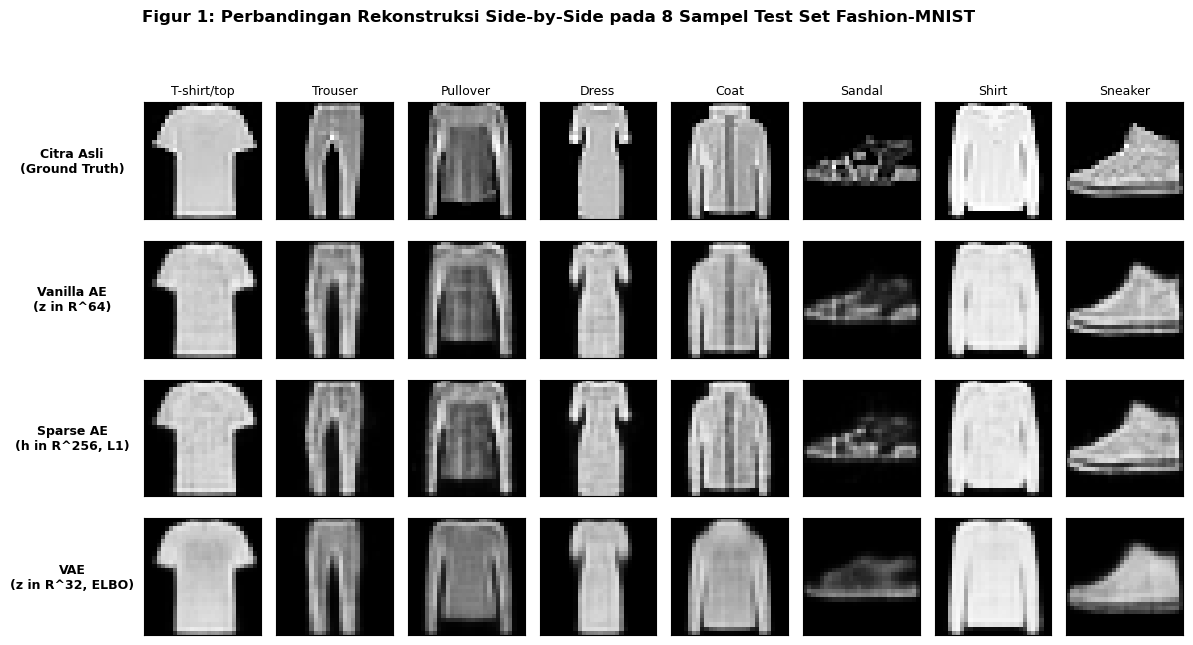

In [25]:
with torch.no_grad():
    rows = [
        ("Citra Asli\n(Ground Truth)", x8.cpu()),
        ("Vanilla AE\n(z in R^64)", vanilla_ae(x8)[0].cpu()),
        ("Sparse AE\n(h in R^256, L1)", sparse_ae(x8)[0].cpu()),
        ("VAE\n(z in R^32, ELBO)", vae.decode(vae.encode(x8)[0]).cpu()),
    ]

fig, axes = plt.subplots(4, 8, figsize=(12.8, 6.6))
fig.suptitle("Figur 1: Perbandingan Rekonstruksi Side-by-Side pada 8 Sampel Test Set Fashion-MNIST", fontsize=12, fontweight="bold", y=0.98)
for r, (title, imgs) in enumerate(rows):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(CLASSES[y8[c]], fontsize=9)
    axes[r, 0].set_ylabel(title, rotation=0, labelpad=52, va="center", fontsize=9, fontweight="bold")

plt.tight_layout(rect=[0.06, 0.0, 1.0, 0.94])
plt.savefig(f"{RESULTS_DIR}/figure1_reconstruction_grid.png", dpi=300, bbox_inches="tight")
plt.show()

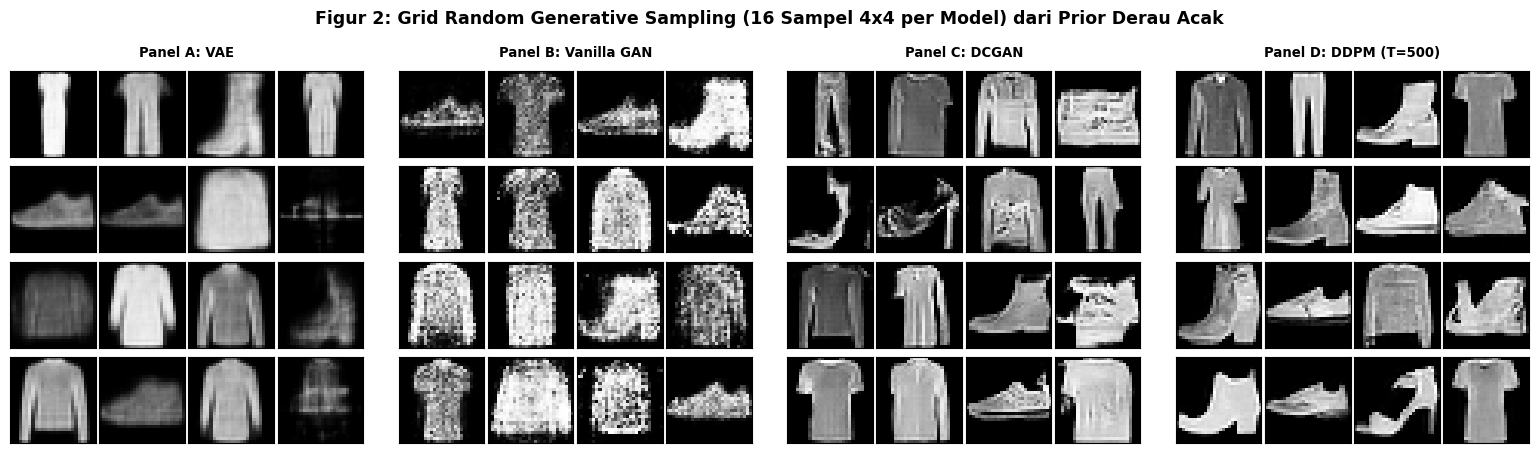

In [26]:
set_seed()
samples = [
    ("Panel A: VAE", vae.sample(16).cpu()),
    ("Panel B: Vanilla GAN", vanilla_g.sample(16).cpu()),
    ("Panel C: DCGAN", dcgan_g.sample(16).cpu()),
    ("Panel D: DDPM (T=500)", ddpm.sample(16).cpu()),
]

fig = plt.figure(figsize=(15.5, 4.5))
fig.suptitle("Figur 2: Grid Random Generative Sampling (16 Sampel 4x4 per Model) dari Prior Derau Acak", fontsize=12.5, fontweight="bold", y=0.99)
outer = fig.add_gridspec(1, 4, wspace=0.10, top=0.86, bottom=0.02, left=0.01, right=0.99)
for p, (name, imgs) in enumerate(samples):
    ax_t = fig.add_subplot(outer[0, p])
    ax_t.set_title(name, fontsize=9.5, fontweight="bold", pad=8)
    ax_t.axis("off")
    inner = outer[0, p].subgridspec(4, 4, wspace=0.04, hspace=0.04)
    for i in range(16):
        ax = fig.add_subplot(inner[i // 4, i % 4])
        ax.imshow(imgs[i, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])

plt.savefig(f"{RESULTS_DIR}/figure2_generative_sampling.png", dpi=300, bbox_inches="tight")
plt.show()

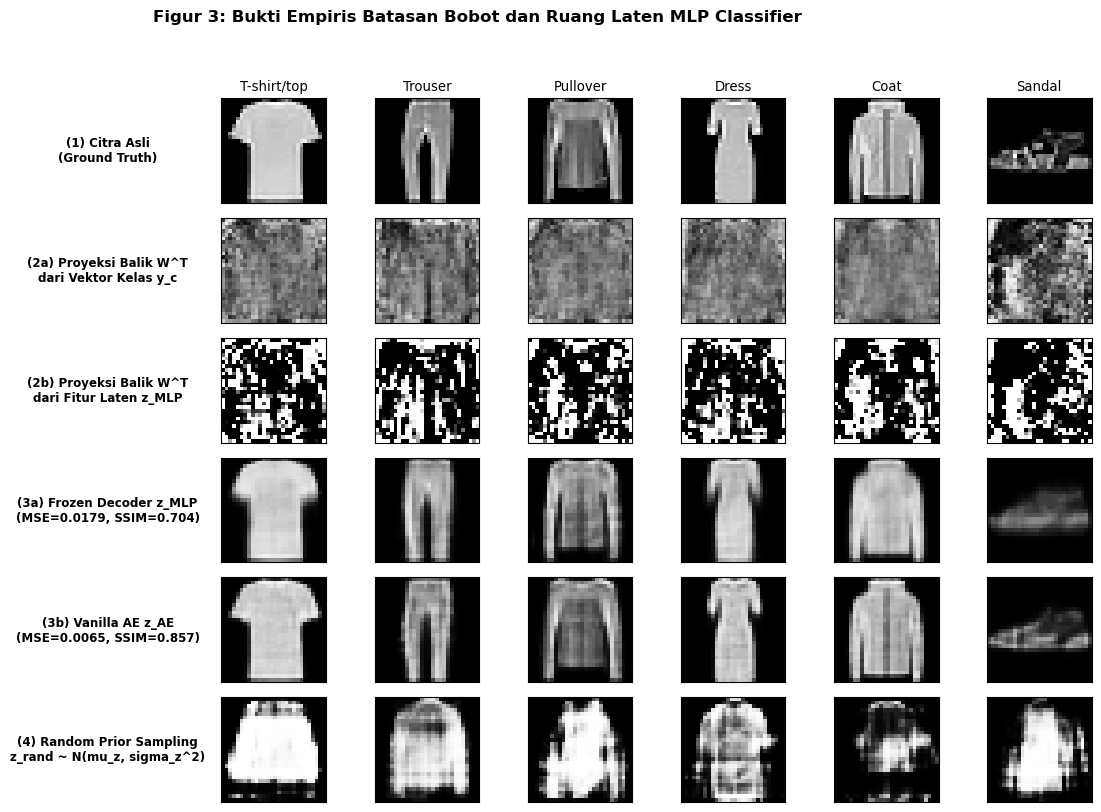

In [27]:
x6, y6 = x8[:6], y8[:6].to(DEVICE)
with torch.no_grad():
    z6 = mlp.extract_latent(x6)
    all_z = torch.cat([mlp.extract_latent(bx.to(DEVICE)).cpu() for bx, _ in test_loader])
    z_rand = all_z.mean(0, keepdim=True).to(DEVICE) + all_z.std(0, keepdim=True).to(DEVICE) * torch.randn(6, 64, device=DEVICE)
    rows3 = [
        ("(1) Citra Asli\n(Ground Truth)", x6.cpu()),
        ("(2a) Proyeksi Balik W^T\ndari Vektor Kelas y_c", mlp.top_down_from_class(F.one_hot(y6, 10).float()).cpu()),
        ("(2b) Proyeksi Balik W^T\ndari Fitur Laten z_MLP", mlp.transpose_from_latent(z6).cpu()),
        (f"(3a) Frozen Decoder z_MLP\n(MSE={rec_frozen['test_mse']:.4f}, SSIM={rec_frozen['test_ssim']:.3f})", frozen_dec(z6).cpu()),
        (f"(3b) Vanilla AE z_AE\n(MSE={rec_vanilla['test_mse']:.4f}, SSIM={rec_vanilla['test_ssim']:.3f})", vanilla_ae(x6)[0].cpu()),
        ("(4) Random Prior Sampling\nz_rand ~ N(mu_z, sigma_z^2)", frozen_dec(z_rand).cpu()),
    ]

fig, axes = plt.subplots(6, 6, figsize=(13.5, 8.2))
fig.suptitle("Figur 3: Bukti Empiris Batasan Bobot dan Ruang Laten MLP Classifier", fontsize=12, fontweight="bold", y=0.985)
for r, (title, imgs) in enumerate(rows3):
    for c in range(6):
        axes[r, c].imshow(imgs[c, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(CLASSES[y6[c].item()], fontsize=9.5)
    axes[r, 0].set_ylabel(title, rotation=0, labelpad=82, va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout(rect=[0.13, 0.0, 1.0, 0.955])
plt.savefig(f"{RESULTS_DIR}/figure3_mlp_limitations.png", dpi=300, bbox_inches="tight")
plt.show()

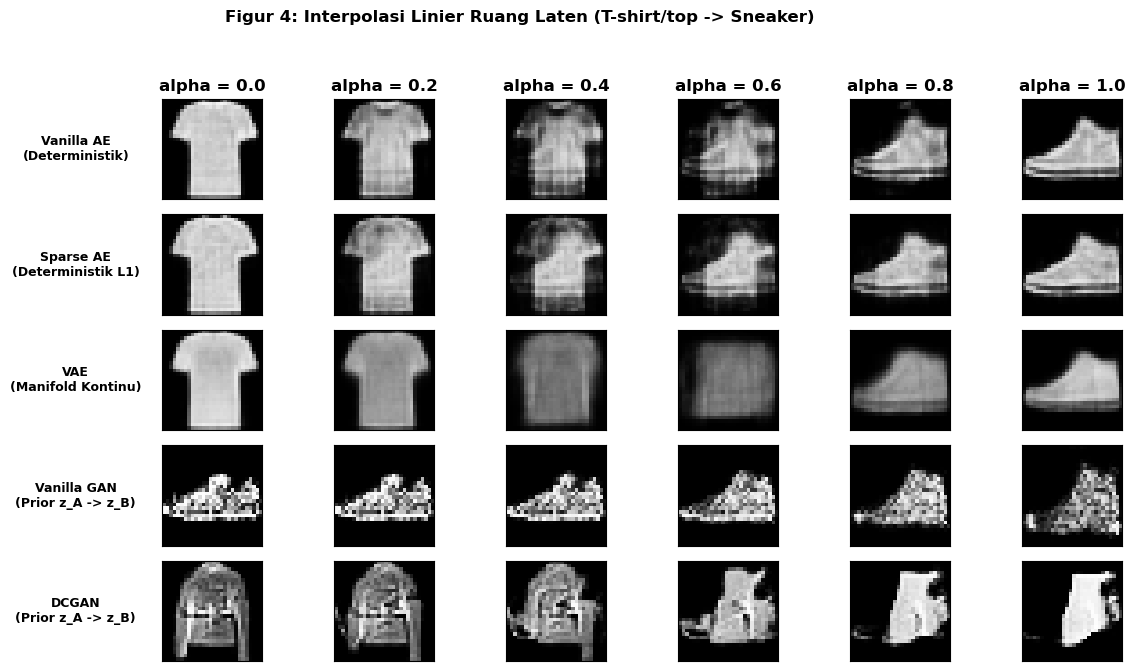

In [28]:
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
xa, xb = x8[0:1], x8[7:8]

with torch.no_grad():
    za_ae, zb_ae = vanilla_ae.encode(xa), vanilla_ae.encode(xb)
    za_sa, zb_sa = sparse_ae.encode(xa), sparse_ae.encode(xb)
    za_va, zb_va = vae.encode(xa)[0], vae.encode(xb)[0]
    set_seed(123)
    za_g, zb_g = torch.randn(1, 100, device=DEVICE), torch.randn(1, 100, device=DEVICE)
    rows4 = [
        ("Vanilla AE\n(Deterministik)",  [vanilla_ae.decode((1-a)*za_ae + a*zb_ae).cpu()[0, 0] for a in alphas]),
        ("Sparse AE\n(Deterministik L1)",   [sparse_ae.decode((1-a)*za_sa + a*zb_sa).cpu()[0, 0] for a in alphas]),
        ("VAE\n(Manifold Kontinu)",         [vae.decode((1-a)*za_va + a*zb_va).cpu()[0, 0] for a in alphas]),
        ("Vanilla GAN\n(Prior z_A -> z_B)", [((vanilla_g((1-a)*za_g + a*zb_g)+1)*0.5).cpu()[0, 0] for a in alphas]),
        ("DCGAN\n(Prior z_A -> z_B)",       [((dcgan_g((1-a)*za_g + a*zb_g)+1)*0.5).cpu()[0, 0] for a in alphas]),
    ]

fig, axes = plt.subplots(5, 6, figsize=(13.5, 6.8))
fig.suptitle("Figur 4: Interpolasi Linier Ruang Laten (T-shirt/top -> Sneaker)", fontsize=12, fontweight="bold", y=0.98)
for r, (title, imgs) in enumerate(rows4):
    for c, a in enumerate(alphas):
        axes[r, c].imshow(imgs[c], cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(f"alpha = {a:.1f}", fontweight="bold")
    axes[r, 0].set_ylabel(title, rotation=0, labelpad=62, va="center", fontsize=9, fontweight="bold")

plt.tight_layout(rect=[0.09, 0.0, 1.0, 0.945])
plt.savefig(f"{RESULTS_DIR}/figure4_latent_interpolation.png", dpi=300, bbox_inches="tight")
plt.show()

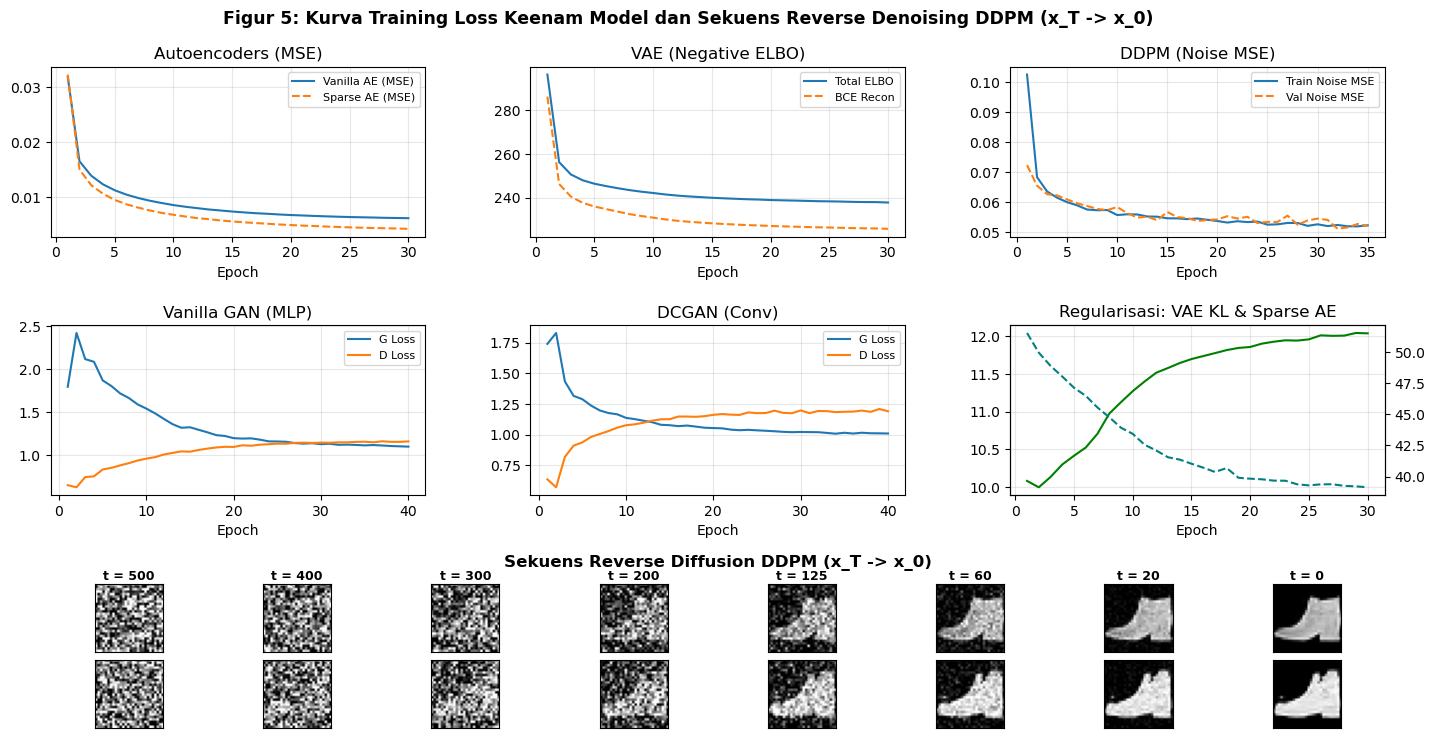

Selesai! Seluruh 5 figur dan JSON tersimpan di folder results/


In [29]:
set_seed(SEED + 10)
_, traj = ddpm.sample(2, save_steps=[500, 400, 300, 200, 125, 60, 20, 0])

fig = plt.figure(figsize=(14.5, 7.6))
fig.suptitle("Figur 5: Kurva Training Loss Keenam Model dan Sekuens Reverse Denoising DDPM (x_T -> x_0)", fontsize=12.5, fontweight="bold", y=0.985)
gs = fig.add_gridspec(3, 3, height_ratios=[1.0, 1.0, 0.85], hspace=0.55, wspace=0.28, top=0.91, bottom=0.04, left=0.06, right=0.98)

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(range(1, 31), histories["vanilla_ae"], label="Vanilla AE (MSE)")
ax1.plot(range(1, 31), histories["sparse_ae"], "--", label="Sparse AE (MSE)")
ax1.set_title("Autoencoders (MSE)"); ax1.set_xlabel("Epoch"); ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(range(1, 31), histories["vae_elbo"], label="Total ELBO")
ax2.plot(range(1, 31), histories["vae_bce"], "--", label="BCE Recon")
ax2.set_title("VAE (Negative ELBO)"); ax2.set_xlabel("Epoch"); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(range(1, 36), histories["ddpm_train"], label="Train Noise MSE")
ax3.plot(range(1, 36), histories["ddpm_val"], "--", label="Val Noise MSE")
ax3.set_title("DDPM (Noise MSE)"); ax3.set_xlabel("Epoch"); ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

ax4 = fig.add_subplot(gs[1, 0])
ax4.plot(range(1, 41), histories["vgan_g"], label="G Loss"); ax4.plot(range(1, 41), histories["vgan_d"], label="D Loss")
ax4.set_title("Vanilla GAN (MLP)"); ax4.set_xlabel("Epoch"); ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
ax5.plot(range(1, 41), histories["dcgan_g"], label="G Loss"); ax5.plot(range(1, 41), histories["dcgan_d"], label="D Loss")
ax5.set_title("DCGAN (Conv)"); ax5.set_xlabel("Epoch"); ax5.legend(fontsize=8); ax5.grid(alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
ax6.plot(range(1, 31), histories["vae_kld"], color="green", label="VAE KL Div")
ax6t = ax6.twinx()
ax6t.plot(range(1, 31), histories["sparse_ratio"], "--", color="teal", label="Sparsity (%)")
ax6.set_title("Regularisasi: VAE KL & Sparse AE"); ax6.set_xlabel("Epoch"); ax6.grid(alpha=0.3)

traj_title = fig.add_subplot(gs[2, :]); traj_title.set_title("Sekuens Reverse Diffusion DDPM (x_T -> x_0)", fontweight="bold", pad=12); traj_title.axis("off")
traj_gs = gs[2, :].subgridspec(2, len(traj), wspace=0.08, hspace=0.12)
for si, (t_val, imgs) in enumerate(traj):
    for rs in range(2):
        ax = fig.add_subplot(traj_gs[rs, si])
        ax.imshow(imgs[rs, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if rs == 0: ax.set_title(f"t = {t_val}", fontsize=9, fontweight="bold", pad=3)

plt.savefig(f"{RESULTS_DIR}/figure5_loss_and_ddpm_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()
print("Selesai! Seluruh 5 figur dan JSON tersimpan di folder results/")